In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
# 1. Load the file
path = "/content/latents_8_92160.pt"
data = torch.load(path, map_location=torch.device('cpu'))

# 2. Extract components
saved_latents = data["latents"]
# Assuming meta was saved as a tensor of [lat, lon]
saved_meta = data["meta"]
# 3. Print Summary Stats
print("--- 📂 File Inspection: latents.pt ---")
print(f"Total Samples:    {saved_latents.shape[0]}")
print(f"Latent Shape:     {saved_latents.shape[1]}")

# 4. Detailed Metric Breakdown (First 5 Samples)
print("\n--- 🛰️ Extracted Metrics Per Sample ---")
header = f"{'Idx':<5} | {'Lat':<10} | {'Lon':<10} | {'Cloud':<8} | {'Mean Elev':<10} | {'Std Elev':<10} | {'Range Elev':<10} |{'Time angle':<10} | Latent Head"
print(header)
print("-" * len(header))

for i in range(min(5, len(saved_latents))):
    # If you saved extra metrics in 'meta' or a separate dict, adjust indexing here:
    lat, lon, cloud_score, mean_elev, std_elev, range_elev, time = saved_meta[i].tolist()

    # Example of how to pull the first few values of the latent for a "fingerprint"
    # Fix: Flatten the tensor before taking the first 3 elements to get a flat list of numbers
    fingerprint = saved_latents[i].flatten()[:3].tolist()
    fp_str = ", ".join([f"{x:.3f}" for x in fingerprint])

    print(f"{i:<5} | {lat:<10.4f} | {lon:<10.4f} | {cloud_score:<8.4f} | {mean_elev:<10.2f} | {std_elev:<10.2f} | {range_elev:<10.2f} | {time:<10.2f} | {fp_str}")

# 5. Numerical Health Check
print("\n--- 🔍 Numerical Health Check ---")
lat_std = saved_latents.std(dim=0).mean().item()
print(f"Average Latent Std Dev: {lat_std:.6f}")

if lat_std < 1e-6:
    print("⚠️  CRITICAL: Latent vectors are identical across samples. Check model input/normalization.")
elif torch.isnan(saved_latents).any():
    print("❌ ERROR: NaNs detected in the saved tensors.")
else:
    print("✅ Latents appear diverse and healthy.")

--- 📂 File Inspection: latents.pt ---
Total Samples:    92160
Latent Shape:     192

--- 🛰️ Extracted Metrics Per Sample ---
Idx   | Lat        | Lon        | Cloud    | Mean Elev  | Std Elev   | Range Elev |Time angle | Latent Head
-----------------------------------------------------------------------------------------------------------
0     | 38.5666    | 111.5139   | 0.0000   | 1671.47    | 89.77      | 449.00     | 3.17       | -0.022, -0.279, -0.124
1     | 69.0627    | -91.5976   | 2.0000   | 183.71     | 8.12       | 48.00      | 2.90       | -0.271, 0.240, 0.037
2     | 11.4172    | 104.8779   | 0.1140   | 8.73       | 1.09       | 11.00      | 1.46       | -0.130, 0.179, -0.384
3     | 54.9352    | -72.0232   | 3.9155   | 439.94     | 18.00      | 75.00      | 5.89       | -0.402, 0.137, -0.133
4     | 26.2363    | 71.6623    | 0.0000   | 210.02     | 1.99       | 14.00      | 0.59       | -0.048, -0.314, -0.368

--- 🔍 Numerical Health Check ---
Average Latent Std Dev: 0.234

In [5]:
import umap
from sklearn.mixture import BayesianGaussianMixture
import matplotlib.pyplot as plt
import numpy as np

def compute_biome_embeddings(X, n_neighbors=30, n_components=10, min_dist=0.1):
    """
    Handles the heavy lifting of UMAP dimensionality reduction.
    Returns the low-dimensional embedding.
    """
    # 1. Prepare Data
    f_array = X.detach().cpu().numpy() if hasattr(X, 'detach') else X

    # 2. UMAP Dimensionality Reduction
    print(f"Reducing dimensions with UMAP (n_components={n_components})...")
    reducer = umap.UMAP(
        n_neighbors=n_neighbors,
        n_components=n_components,
        min_dist=min_dist,
        metric='cosine',
        random_state=42
    )
    embedding = reducer.fit_transform(f_array)

    return embedding

def plot_gmm_biome_map(embedding, Lats, Longs, n_biomes=10, output_filename="gmm_biome_map.png"):
    """
    Clusters the embedding using Bayesian GMM and plots the results
    geographically using Lats and Longs.
    """
    # 1. Clustering with Bayesian GMM
    # weight_concentration_prior: lower values = more aggressive cluster pruning.
    print(f"Fitting Bayesian GMM with max {n_biomes} clusters...")
    gmm = BayesianGaussianMixture(
        n_components=n_biomes,
        weight_concentration_prior=1e-3,
        max_iter=1000,
        random_state=42
    )

    cluster_labels = gmm.fit_predict(embedding)

    active_clusters = len(np.unique(cluster_labels))
    print(f"Model settled on {active_clusters} active biomes.")

    # 2. Visualization
    plt.figure(figsize=(15, 8), facecolor='white')

    scatter = plt.scatter(
        Longs, Lats,
        c=cluster_labels,
        cmap='tab20',
        s=5,
        alpha=0.8,
        edgecolors='none'
    )

    plt.colorbar(scatter, label='Biome Cluster ID')
    plt.title(f"GMM Biome Classification (Latent Space)\nActive Clusters: {active_clusters}")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")

    plt.tight_layout()
    plt.savefig(output_filename, dpi=300)
    print(f"Map saved as {output_filename}")
    plt.show()

    return cluster_labels

def plot_cluster_probability_heatmaps(embedding, Lats, Longs, n_biomes=10):
    """
    Fits a GMM and plots a geographic heatmap for each active cluster
    showing the probability of membership.
    """
    # 1. Fit the GMM
    print(f"Fitting Bayesian GMM to compute probabilities...")
    gmm = BayesianGaussianMixture(
        n_components=n_biomes,
        weight_concentration_prior=1e-3,
        max_iter=1000,
        random_state=42
    )
    gmm.fit(embedding)

    # 2. Get Soft Assignments (Probabilities)
    # probabilities shape: (n_samples, n_components)
    probabilities = gmm.predict_proba(embedding)

    # 3. Identify active clusters (where mean weight is above a threshold)
    active_indices = [i for i, weight in enumerate(gmm.weights_) if weight > 0.01]
    n_active = len(active_indices)

    print(f"Plotting heatmaps for {n_active} active clusters...")

    # 4. Create Subplots
    # We'll create a grid to show all heatmaps
    cols = 3
    rows = (n_active + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows), facecolor='white')
    axes = axes.flatten()

    for i, cluster_idx in enumerate(active_indices):
        ax = axes[i]

        # Extract probabilities for this specific cluster
        cluster_probs = probabilities[:, cluster_idx]

        # Plotting the heatmap using scatter with alpha and intensity
        path = ax.scatter(
            Longs, Lats,
            c=cluster_probs,
            cmap='viridis',
            s=5,
            alpha=0.6,
            edgecolors='none'
        )

        ax.set_title(f"Cluster {cluster_idx} Probability\n(Weight: {gmm.weights_[cluster_idx]:.3f})")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        plt.colorbar(path, ax=ax)

    # Remove empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

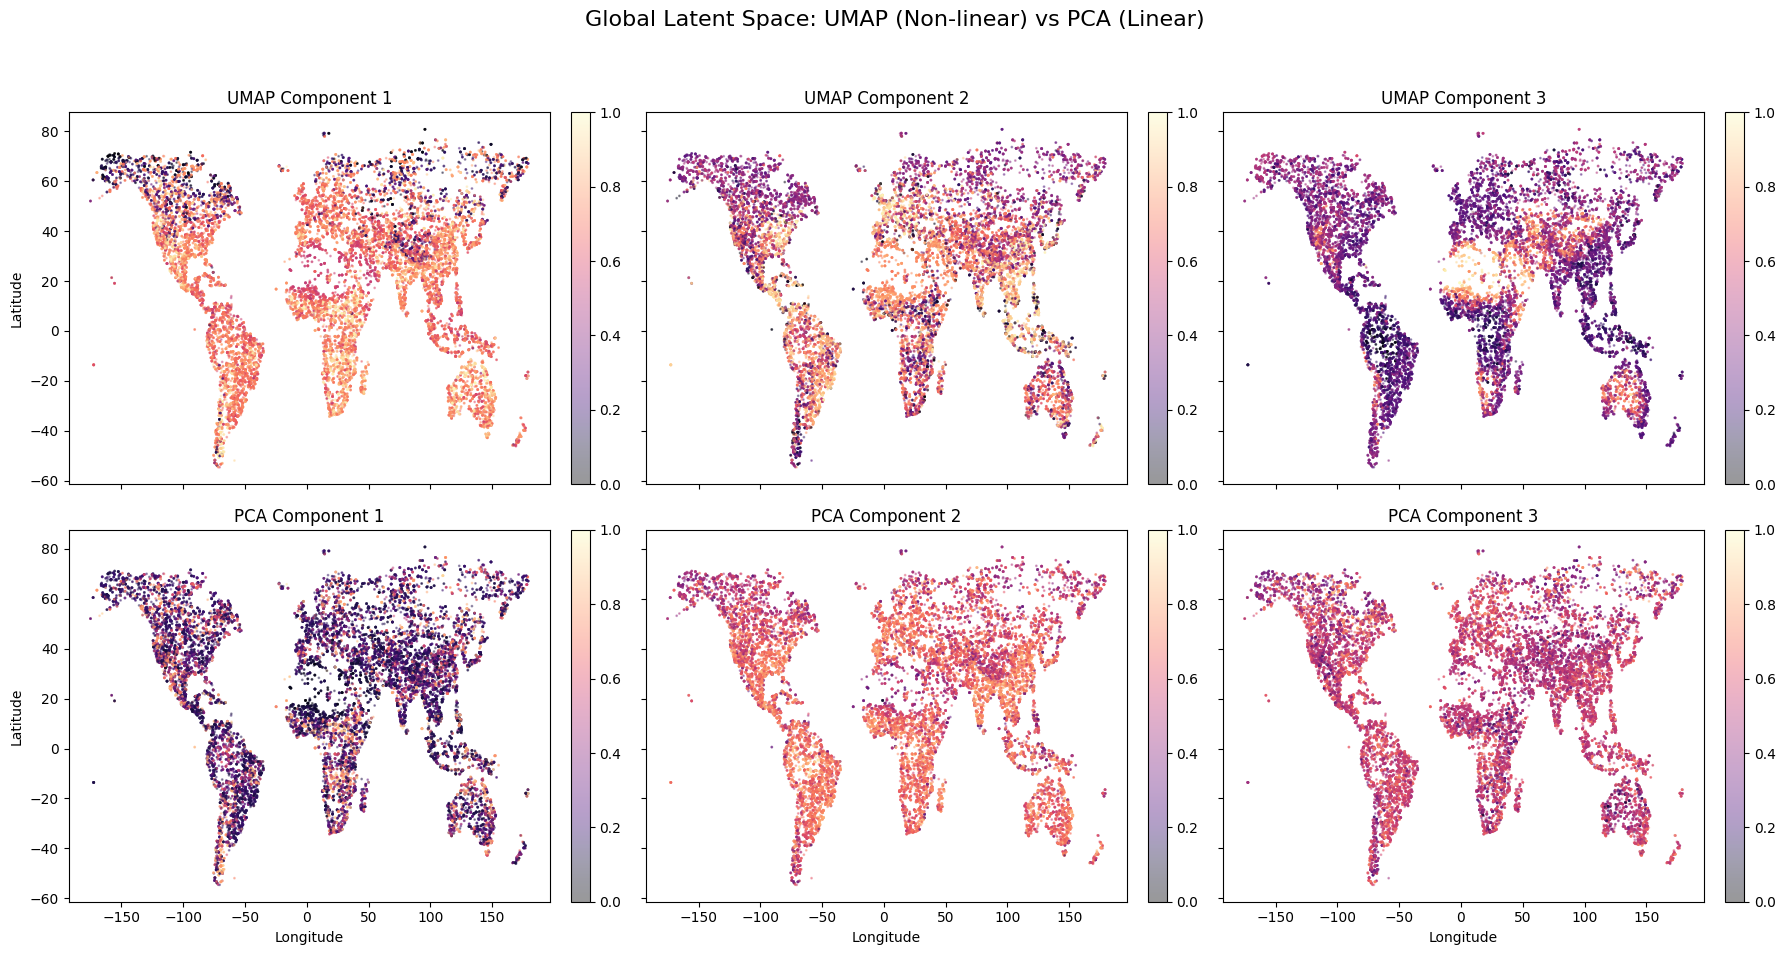

Reducing dimensions with UMAP (n_components=10)...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Fitting Bayesian GMM with max 10 clusters...
Model settled on 10 active biomes.
Map saved as gmm_biome_map.png


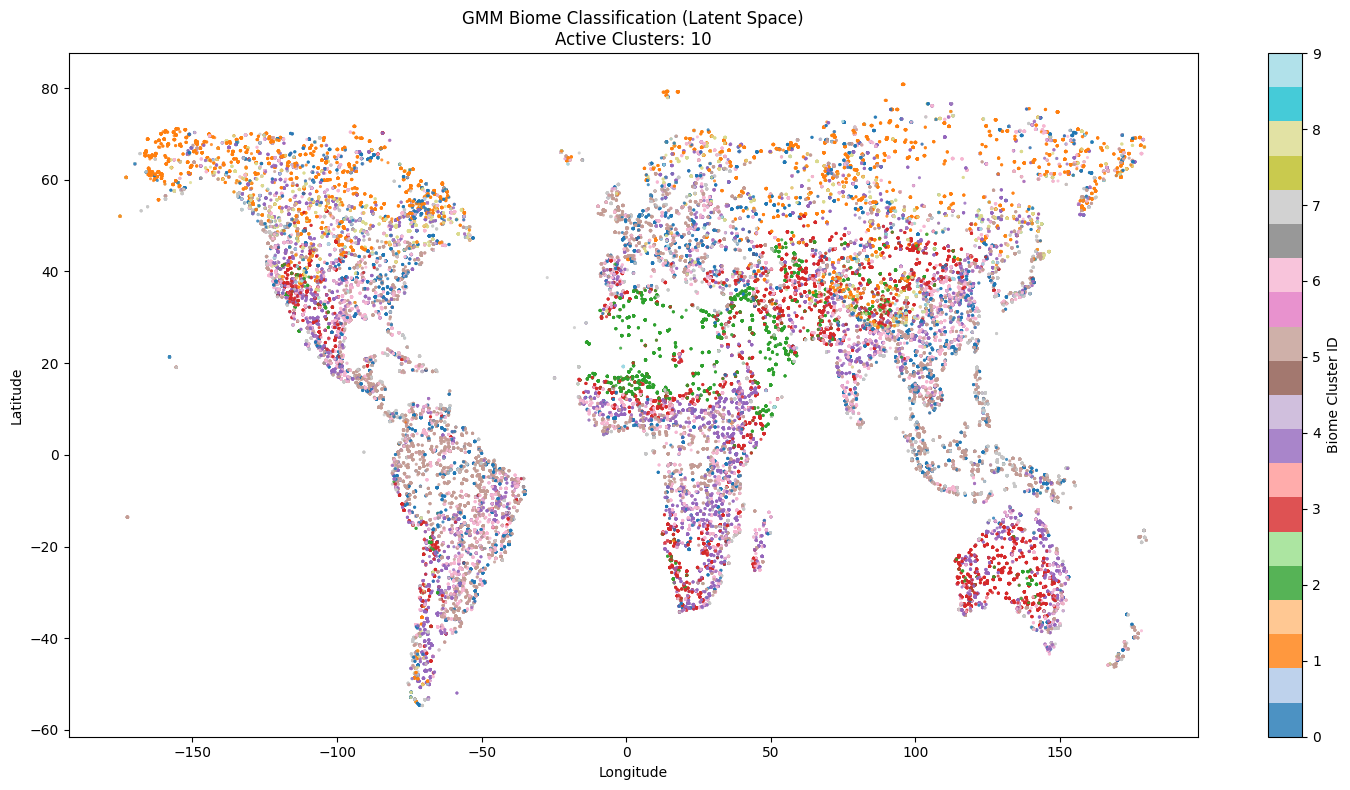

In [4]:
X = saved_latents
Lats = saved_meta[:, 0]
Longs = saved_meta[:, 1]
embedding = compute_biome_embeddings(X)

Fitting Bayesian GMM with max 6 clusters...
Model settled on 6 active biomes.
Map saved as gmm_biome_map.png


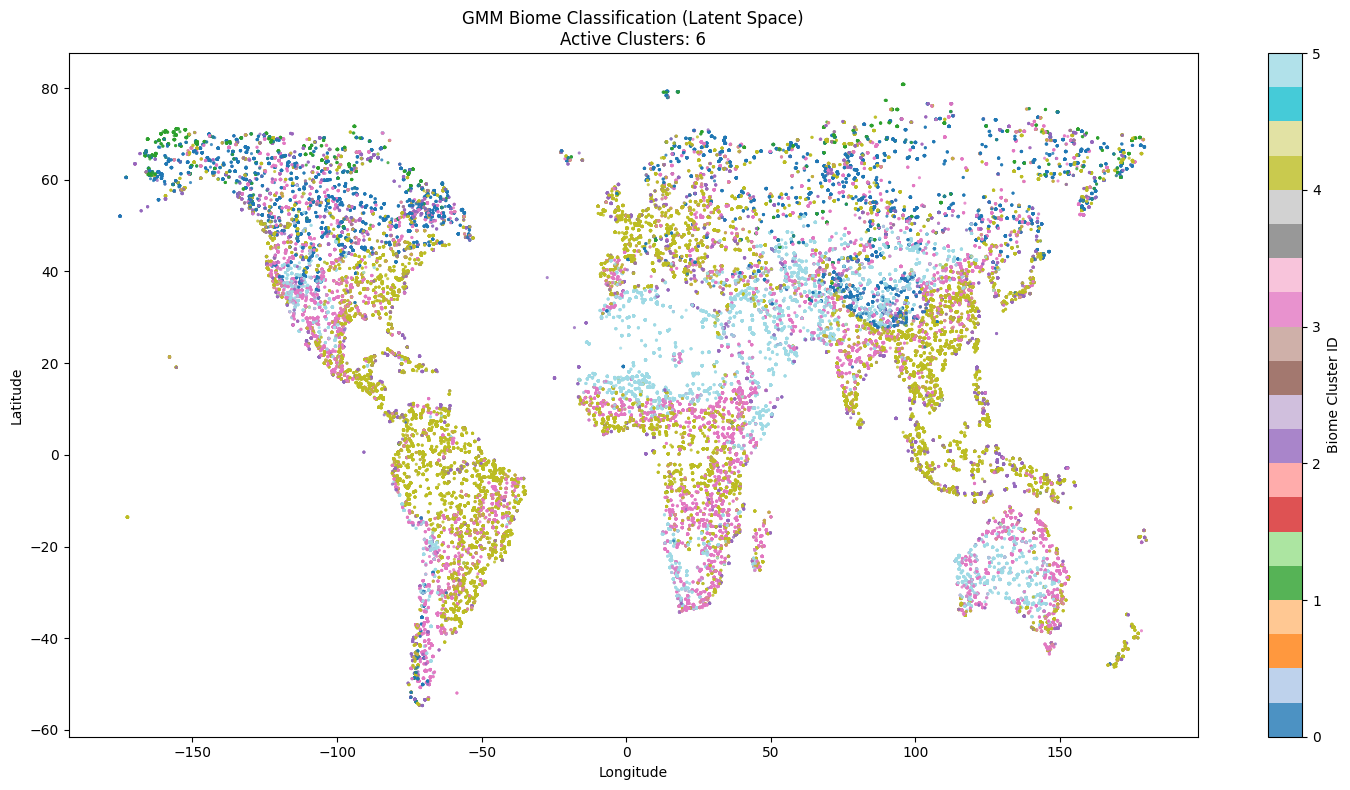

Fitting Bayesian GMM to compute probabilities...
Plotting heatmaps for 6 active clusters...


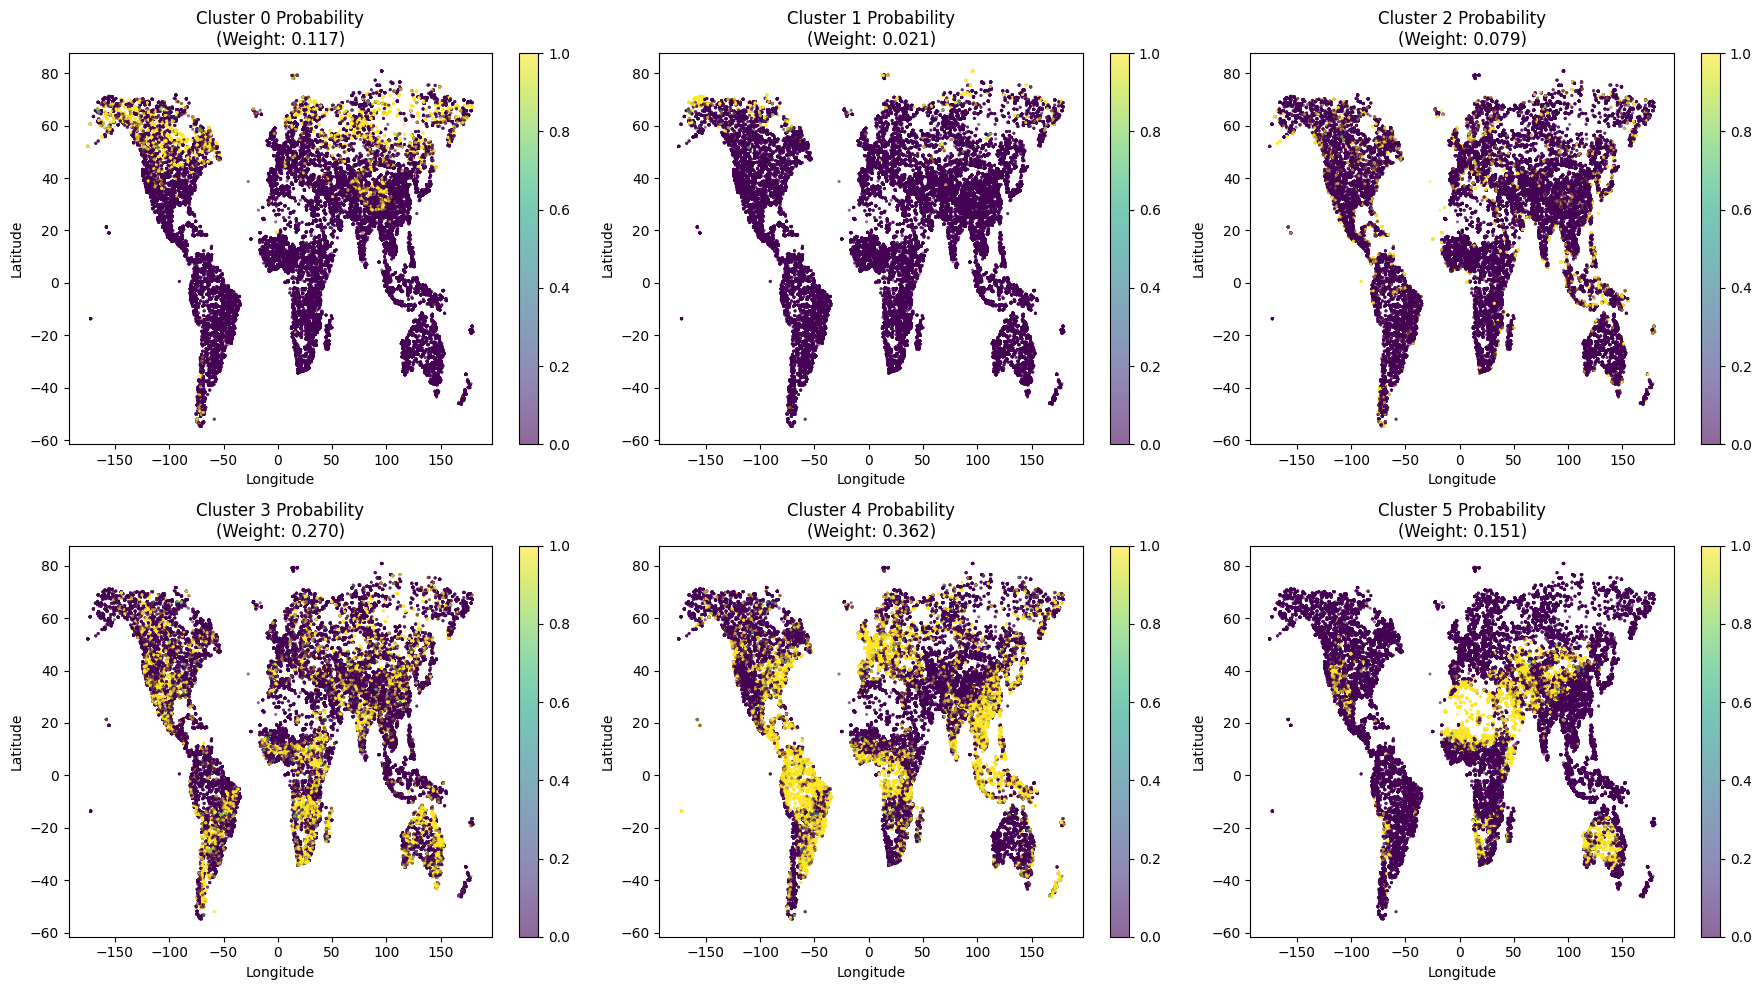

In [7]:
labels = plot_gmm_biome_map(embedding, Lats, Longs, n_biomes=6)
plot_cluster_probability_heatmaps(embedding, Lats, Longs, n_biomes=6)